# OK Cupid Machine learning project
This project takes a dataset from a dating website for scientists. The aim will be to assess the data and determine if there are any useful ways to use machine learning models.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

In [2]:
profiles = pd.read_csv('profiles.csv')
profiles.info()

<class 'pandas.DataFrame'>
RangeIndex: 59946 entries, 0 to 59945
Data columns (total 31 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          59946 non-null  int64  
 1   body_type    54650 non-null  str    
 2   diet         35551 non-null  str    
 3   drinks       56961 non-null  str    
 4   drugs        45866 non-null  str    
 5   education    53318 non-null  str    
 6   essay0       54458 non-null  str    
 7   essay1       52374 non-null  str    
 8   essay2       50308 non-null  str    
 9   essay3       48470 non-null  str    
 10  essay4       49409 non-null  str    
 11  essay5       49096 non-null  str    
 12  essay6       46175 non-null  str    
 13  essay7       47495 non-null  str    
 14  essay8       40721 non-null  str    
 15  essay9       47343 non-null  str    
 16  ethnicity    54266 non-null  str    
 17  height       59943 non-null  float64
 18  income       59946 non-null  int64  
 19  job          51

In [3]:
profiles.nunique()

age               54
body_type         12
diet              18
drinks             6
drugs              3
education         32
essay0         54350
essay1         51516
essay2         48635
essay3         43533
essay4         49260
essay5         48963
essay6         43603
essay7         45554
essay8         39324
essay9         45443
ethnicity        217
height            60
income            13
job               21
last_online    30123
location         199
offspring         15
orientation        3
pets              15
religion          45
sex                2
sign              48
smokes             5
speaks          7647
status             5
dtype: int64

## Data Cleaning
After reviewing the data the potential columns that could be used in the models are isolated and cleaned below. Both the sign and the religion categories have been cleaned to only show the individual signs and not any excess information.

In [4]:
profiles = profiles[['body_type','diet','drinks','drugs','education','height','income','job','offspring','orientation','pets','religion','sex','smokes','sign']]
profiles.nunique()

body_type      12
diet           18
drinks          6
drugs           3
education      32
height         60
income         13
job            21
offspring      15
orientation     3
pets           15
religion       45
sex             2
smokes          5
sign           48
dtype: int64

In [5]:
profiles['sign'] = profiles.sign.str.split().str.get(0)
profiles['religion'] = profiles.religion.str.split().str.get(0)
profiles.nunique()

body_type      12
diet           18
drinks          6
drugs           3
education      32
height         60
income         13
job            21
offspring      15
orientation     3
pets           15
religion        9
sex             2
smokes          5
sign           12
dtype: int64

### Visualisations of discrete variables

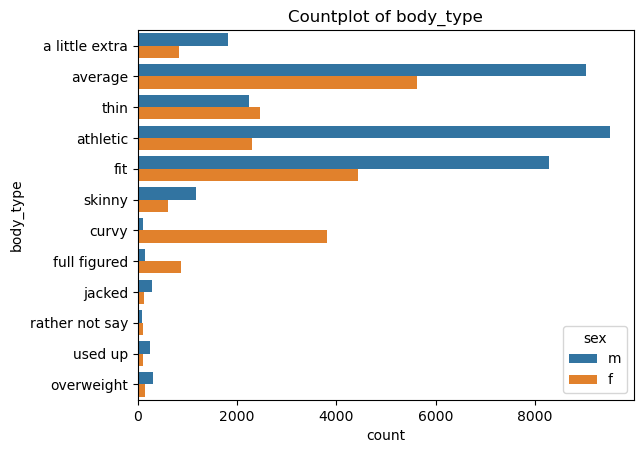

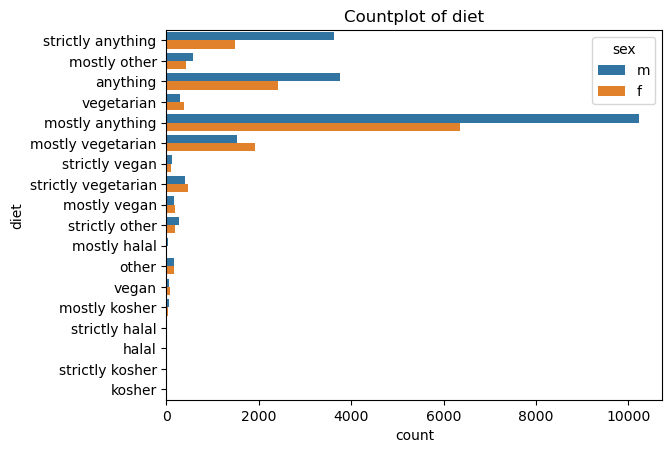

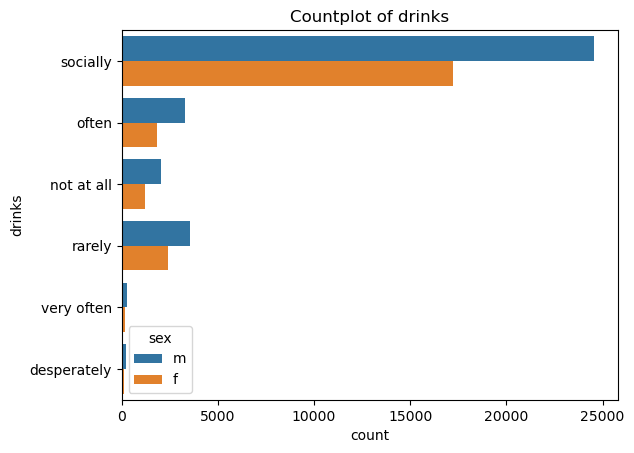

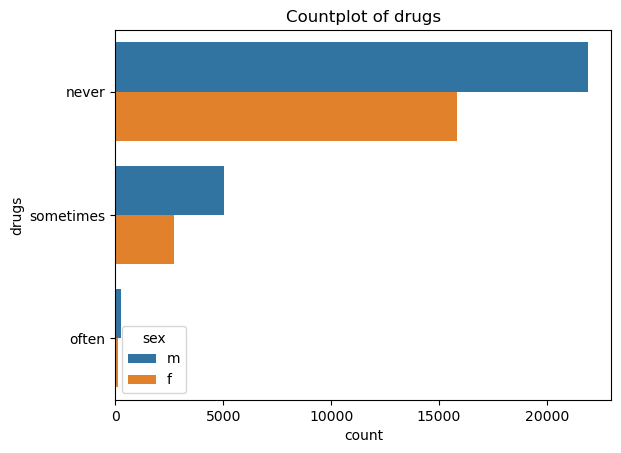

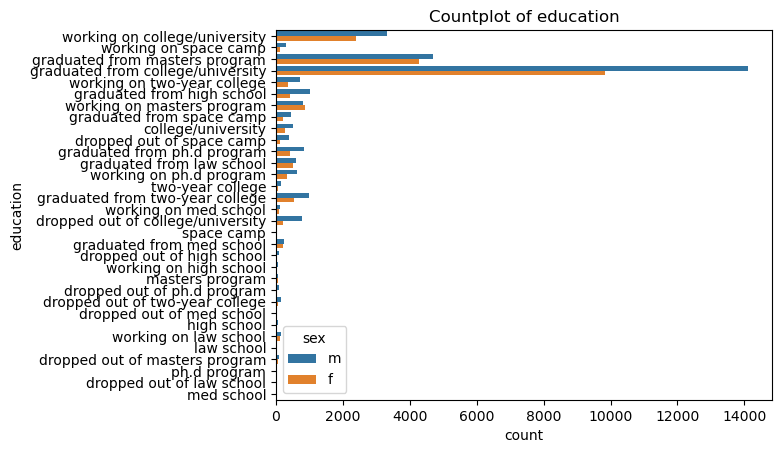

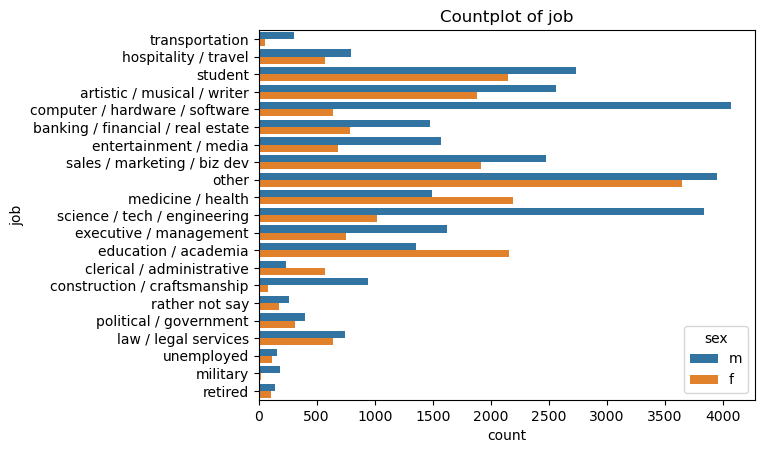

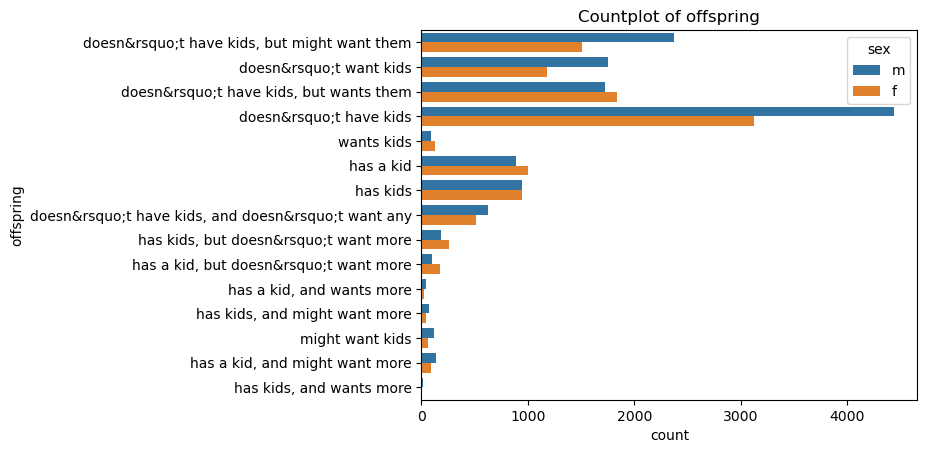

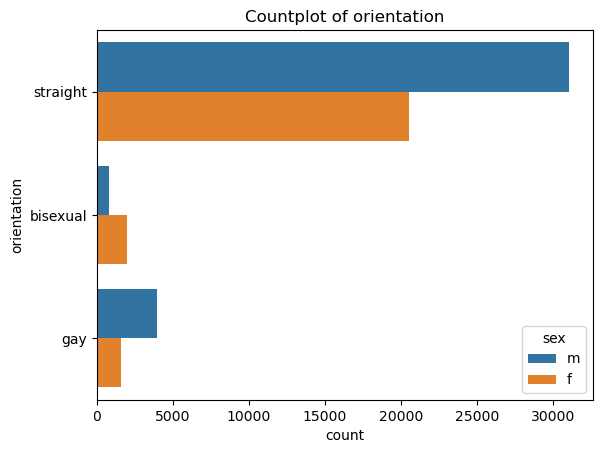

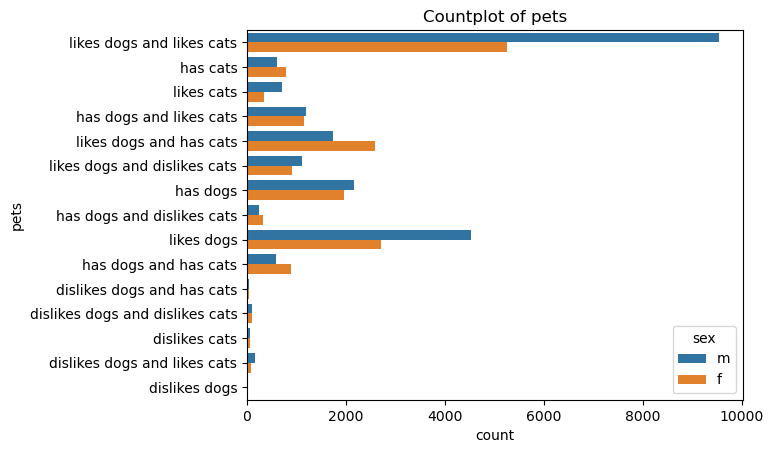

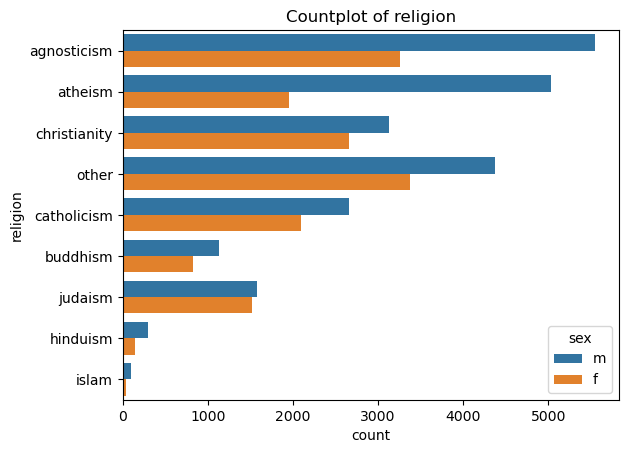

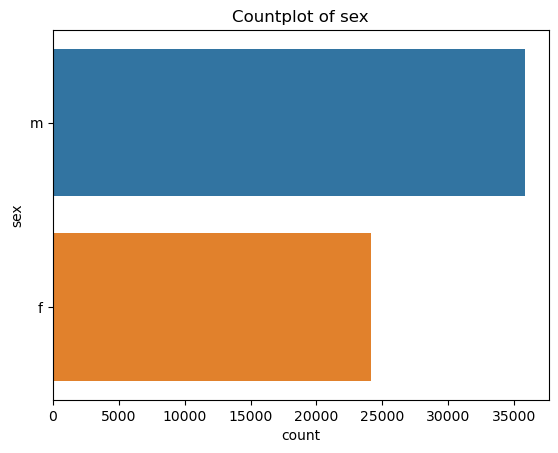

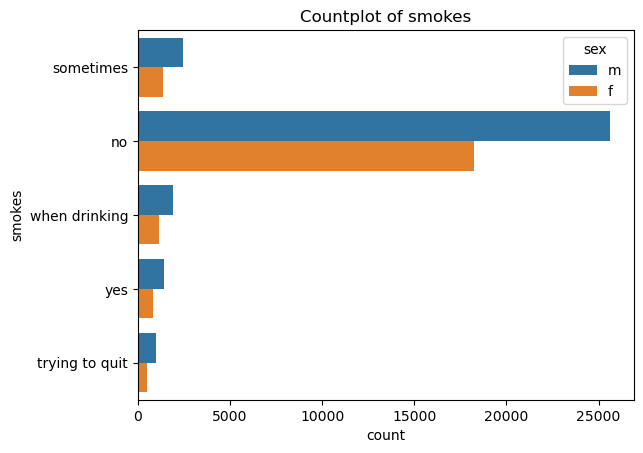

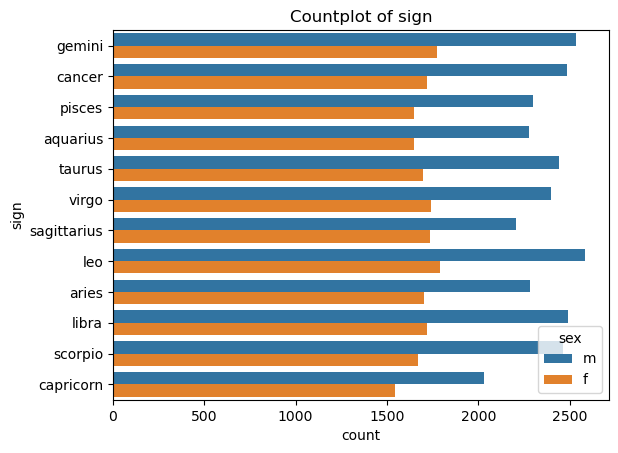

<Figure size 640x480 with 0 Axes>

In [6]:
for x in profiles.columns:
    if profiles[x].dtype == 'str' or profiles[x].dtype == 'object':
        sns.countplot(data = profiles, y = x, hue = 'sex')
        plt.title('Countplot of ' + x)
    plt.show()
plt.clf()

### Visualisations of Continuous variables

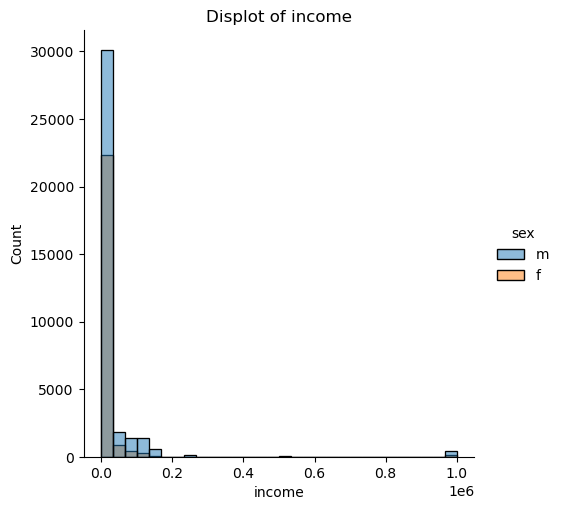

<Figure size 640x480 with 0 Axes>

In [7]:
sns.displot(data = profiles, x = 'income', hue = 'sex', bins = 30)
plt.title('Displot of income')
plt.show()
plt.clf()

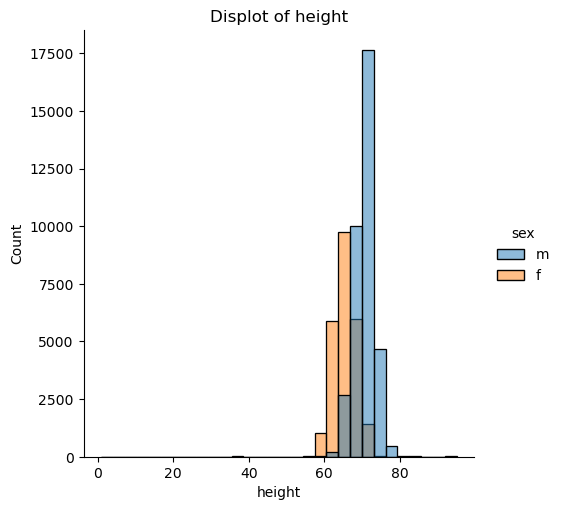

<Figure size 640x480 with 0 Axes>

In [8]:
sns.displot(data = profiles, x = 'height', hue = 'sex', bins = 30)
plt.title('Displot of height')
plt.show()
plt.clf()

# Varaibales against zodiac signs
Visualisations of counts of all variables against zodiac signs to determine whether there are any clear differences by sign for the individual variables.

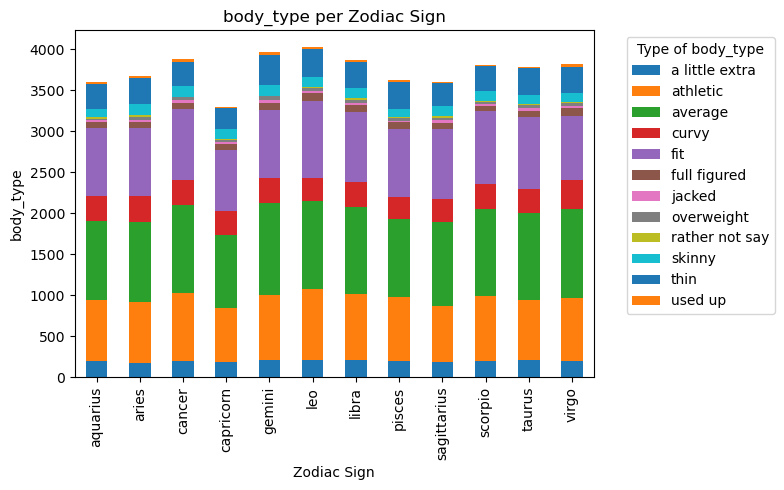

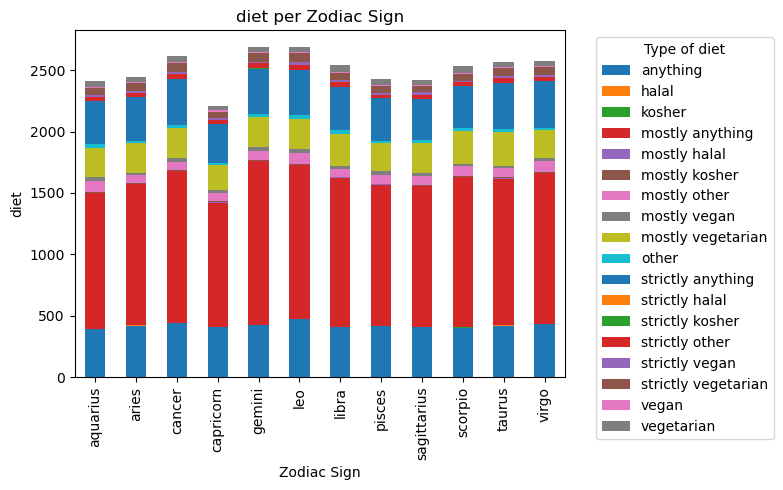

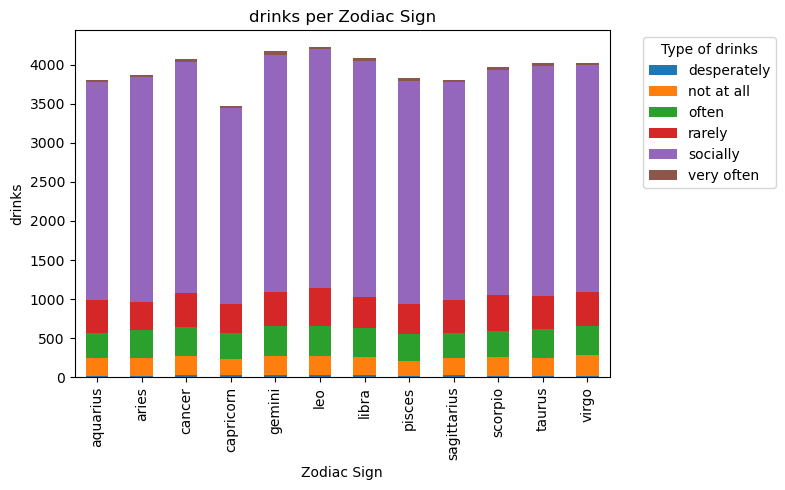

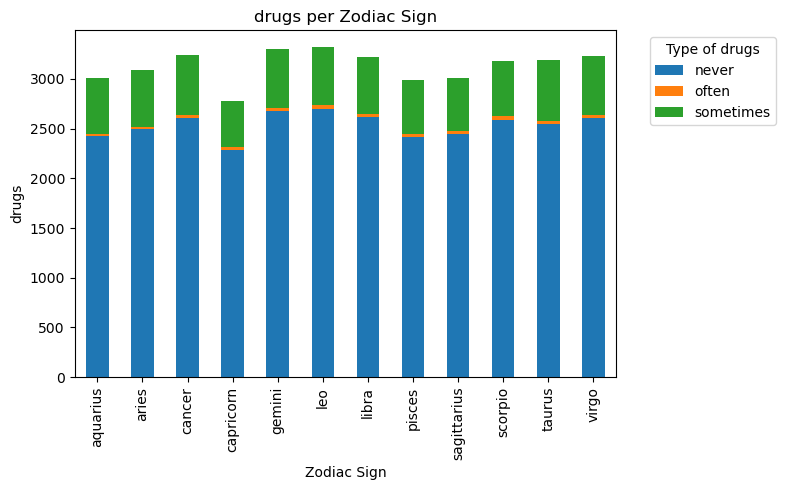

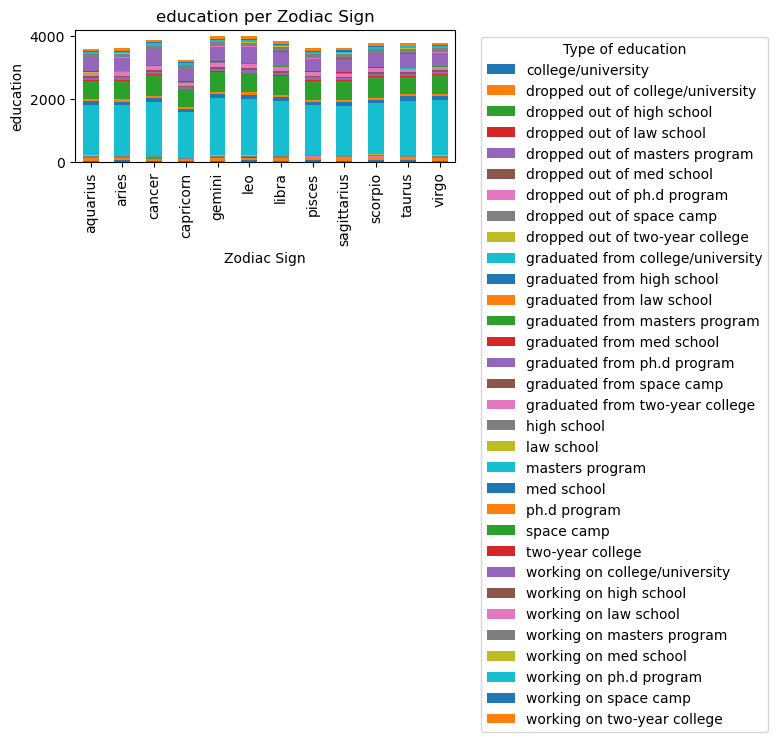

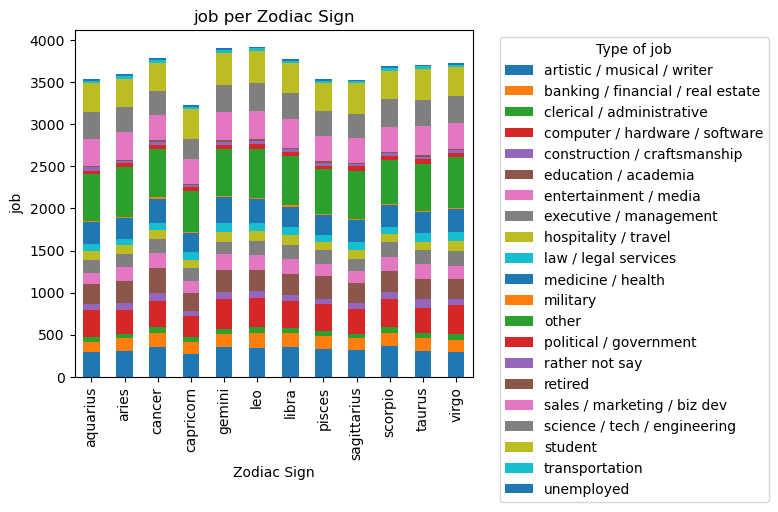

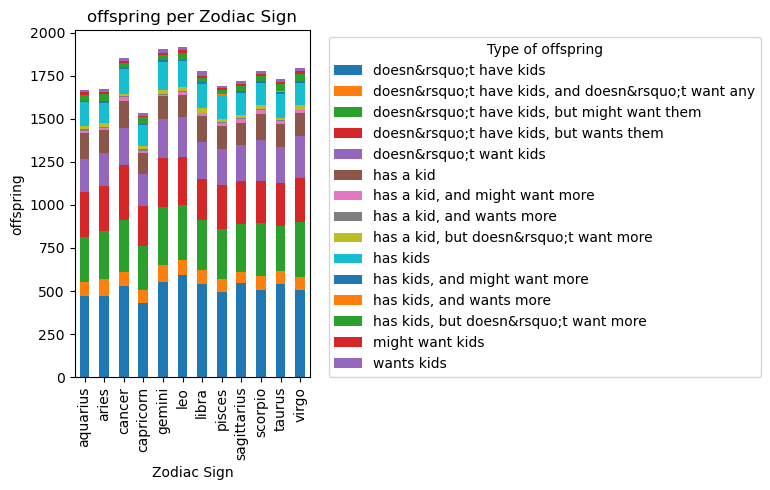

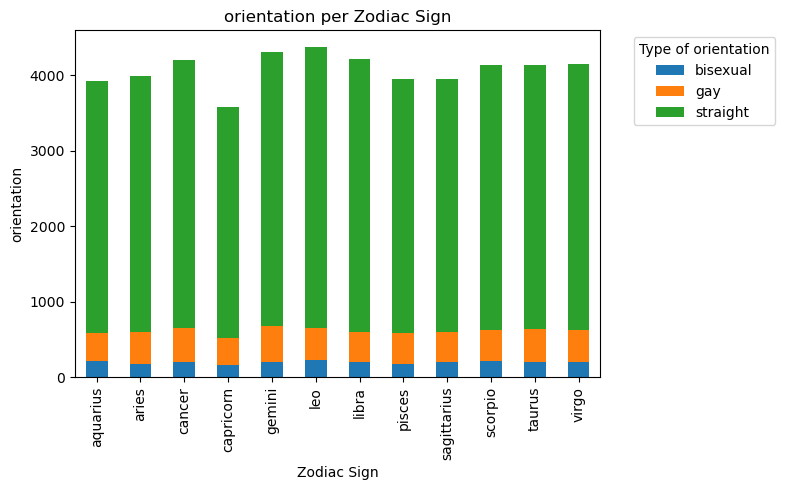

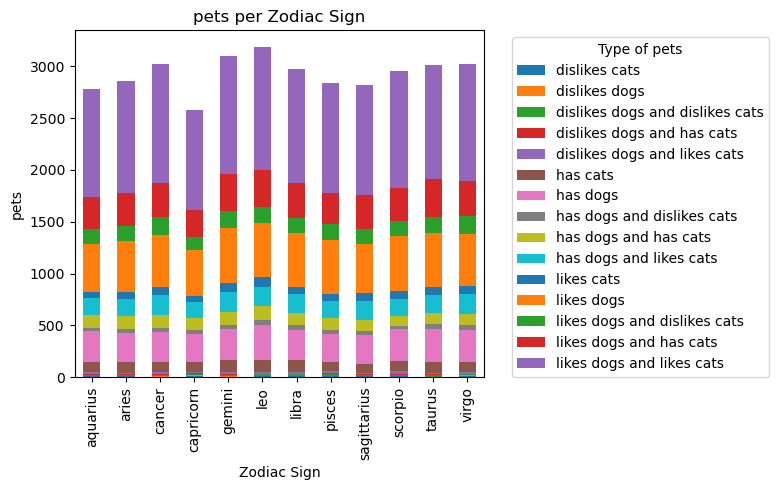

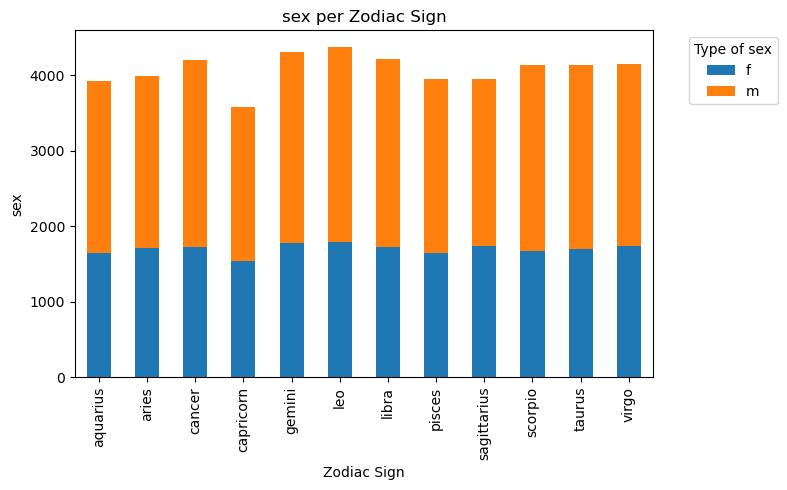

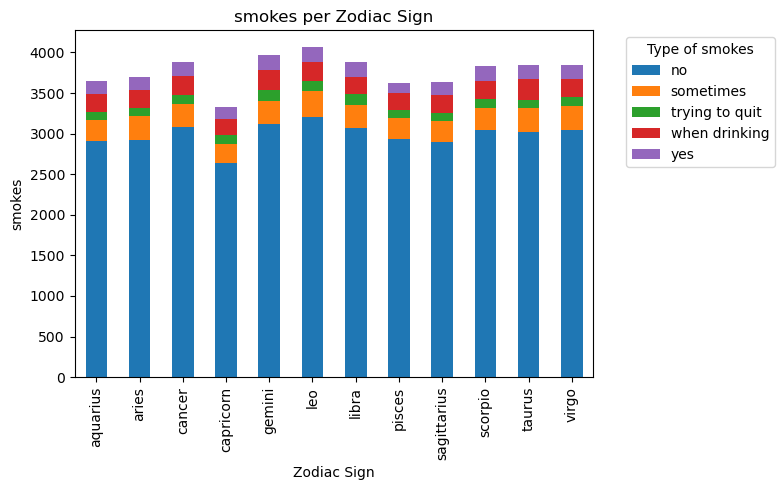

In [9]:
for x in profiles.columns:
    if (x != 'sign') & (profiles[x].dtype == 'str'):
        counts = profiles.groupby(['sign', x]).size().unstack(fill_value=0)
        counts.plot(kind='bar', stacked=True, figsize=(8, 5))
        plt.title(x + ' per Zodiac Sign')
        plt.xlabel('Zodiac Sign')
        plt.ylabel(x)
        plt.xticks(rotation=90) # Keeps X-axis labels horizontal
        plt.legend(title='Type of ' + x, bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()

<Axes: xlabel='height', ylabel='Count'>

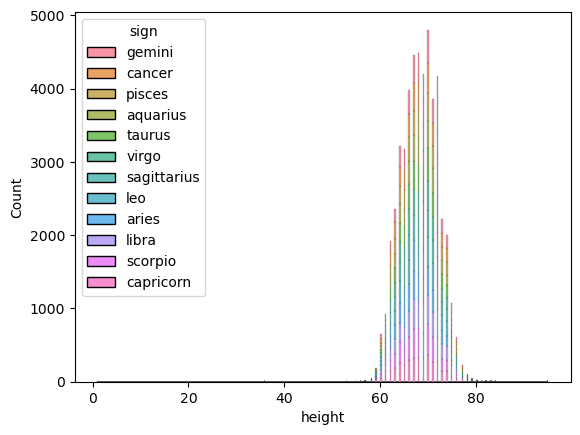

In [10]:
sns.histplot(data = profiles, x = 'height', hue = 'sign',  multiple = 'stack')

Initial basic analysis shows that the distribution of signs across different features is all fairly uniform, suggesting no correlation between any of the features and the zodiac sign.

# Data preparation for madels
Dropping the missing data and adding dummy values for prediction variables, and then creating a traintest split.

In [11]:
cols =  ['body_type','diet','drinks','drugs','education','height','job','offspring','orientation','pets','religion','sex','smokes','sign']
df = profiles[cols].dropna()
df.shape

(7404, 14)

In [12]:
for col in cols[:-1]:
    df = pd.get_dummies(df,columns = [col], prefix = [col], dtype = 'int')
df.head()

,sign,body_type_a little extra,body_type_athletic,body_type_average,body_type_curvy,body_type_fit,body_type_full figured,body_type_jacked,body_type_overweight,body_type_rather not say,...,religion_islam,religion_judaism,religion_other,sex_f,sex_m,smokes_no,smokes_sometimes,smokes_trying to quit,smokes_when drinking,smokes_yes
0,gemini,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,1,0,0,0
1,cancer,0,0,1,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0
7,sagittarius,0,0,1,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,0
14,taurus,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,0
19,pisces,0,1,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0


In [13]:
x = df.iloc[:,1:]
y = df.iloc[:,:1]


In [14]:
x_train, x_test, y_train, y_test = train_test_split(x,y, random_state=0, test_size=0.25)

y_train = y_train.to_numpy().ravel()
y_test = y_test.to_numpy().ravel()

# Building the models
I decided to use 3 diffferent classifier models, random forest, decision tree and k nearest neightbour.

In [15]:
rf = RandomForestClassifier()

rf.fit(x_train,y_train)
rf_pred = rf.predict(x_test)
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

    aquarius       0.04      0.04      0.04       127
       aries       0.08      0.08      0.08       153
      cancer       0.08      0.10      0.09       165
   capricorn       0.07      0.05      0.06       135
      gemini       0.06      0.07      0.07       174
         leo       0.08      0.10      0.09       166
       libra       0.08      0.08      0.08       152
      pisces       0.10      0.11      0.10       148
 sagittarius       0.08      0.07      0.08       151
     scorpio       0.11      0.09      0.10       159
      taurus       0.03      0.02      0.02       148
       virgo       0.08      0.07      0.07       173

    accuracy                           0.08      1851
   macro avg       0.07      0.07      0.07      1851
weighted avg       0.07      0.08      0.07      1851



In [16]:
dt = DecisionTreeClassifier()

dt.fit(x_train,y_train)
dt_pred = rf.predict(x_test)
print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

    aquarius       0.04      0.04      0.04       127
       aries       0.08      0.08      0.08       153
      cancer       0.08      0.10      0.09       165
   capricorn       0.07      0.05      0.06       135
      gemini       0.06      0.07      0.07       174
         leo       0.08      0.10      0.09       166
       libra       0.08      0.08      0.08       152
      pisces       0.10      0.11      0.10       148
 sagittarius       0.08      0.07      0.08       151
     scorpio       0.11      0.09      0.10       159
      taurus       0.03      0.02      0.02       148
       virgo       0.08      0.07      0.07       173

    accuracy                           0.08      1851
   macro avg       0.07      0.07      0.07      1851
weighted avg       0.07      0.08      0.07      1851



In [17]:
knn = KNeighborsClassifier()

knn.fit(x_train,y_train)
knn_pred = rf.predict(x_test)
print(classification_report(y_test, knn_pred))

              precision    recall  f1-score   support

    aquarius       0.04      0.04      0.04       127
       aries       0.08      0.08      0.08       153
      cancer       0.08      0.10      0.09       165
   capricorn       0.07      0.05      0.06       135
      gemini       0.06      0.07      0.07       174
         leo       0.08      0.10      0.09       166
       libra       0.08      0.08      0.08       152
      pisces       0.10      0.11      0.10       148
 sagittarius       0.08      0.07      0.08       151
     scorpio       0.11      0.09      0.10       159
      taurus       0.03      0.02      0.02       148
       virgo       0.08      0.07      0.07       173

    accuracy                           0.08      1851
   macro avg       0.07      0.07      0.07      1851
weighted avg       0.07      0.08      0.07      1851



All three models show similar levels of accuraccy at around 8%. this suggests that the features used are not indicative of the zodiac signs, and that all are similarly accurate.

## Next Steps
The next steps would be to either try a different model to try and predict the zodiac signs of the profiles, or to perform hyper parameter tuning in order to try and get more accurate results from these models. In all likelyhood this will always be a tricky thing to predict without using a highly related variable (month of DOB). However perhaps with mroe data the models could be more accurate.